<a href="https://colab.research.google.com/github/hello189/Image-Classification-with-CNN/blob/main/Image_Classification_with_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install TensorFlow Datasets if needed (uncomment in Colab if missing)
#!pip install -q tensorflow-datasets

import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras import layers, models
import cv2
from tqdm import tqdm
import os

import numpy as np
import time
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, classification_report


print("TensorFlow version:", tf.__version__)
print("TFDS version:", tfds.__version__)

# Check for GPU
gpus = tf.config.list_physical_devices('GPU')
print("GPUs available:", gpus)



TensorFlow version: 2.19.0
TFDS version: 4.9.9
GPUs available: []


In [ ]:
# Load dataset from TFDS

splitstf = [
    "train[:60%]",    # train split
    "train[60%:80%]", # validation split
    "train[80%:]",    # test split
    ]

(ds_train_raw, ds_val_raw, ds_test_raw), ds_info = tfds.load(
    "tf_flowers",
    split=splitstf,
    as_supervised=True,  # (image, label)
    with_info=True
)

num_classes = ds_info.features["label"].num_classes
class_names = ds_info.features["label"].names

print("Number of classes:", num_classes)
print("Class names:", class_names)
print("Training examples:", ds_info.splits["train"].num_examples)

Number of classes: 5
Class names: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Training examples: 3670


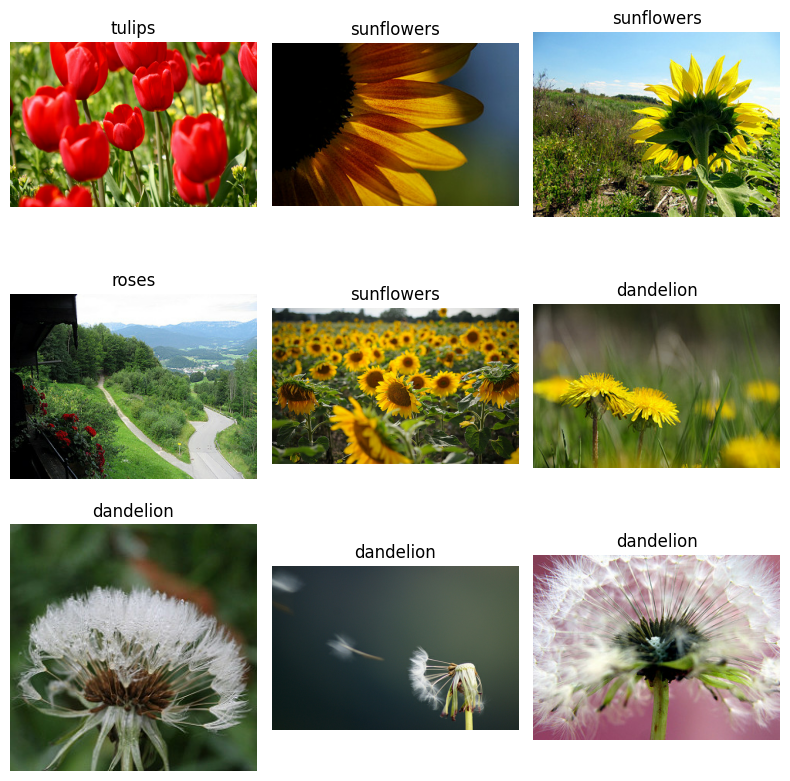

In [ ]:
def show_samples(dataset, class_names, n=9):
    plt.figure(figsize=(8, 8))
    for i, (image, label) in enumerate(dataset.take(n)):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(image)
        plt.title(class_names[int(label)])
        plt.axis("off")
    plt.tight_layout()
    plt.show()

show_samples(ds_train_raw, class_names, n=9)


0: dandelion  -> 557 images
1: daisy      -> 386 images
2: tulips     -> 452 images
3: sunflowers -> 418 images
4: roses      -> 389 images


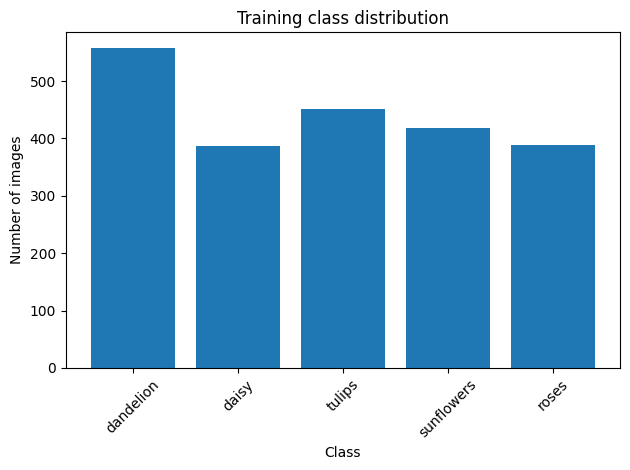

In [ ]:
# Count examples per class in the training split
counts = np.zeros(num_classes, dtype=int)

for _, label in tfds.as_numpy(ds_train_raw):
    counts[label] += 1

for i, cname in enumerate(class_names):
    print(f"{i}: {cname:10s} -> {counts[i]} images")

plt.figure()
plt.bar(range(num_classes), counts)
plt.xticks(range(num_classes), class_names, rotation=45)
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.title("Training class distribution")
plt.tight_layout()
plt.show()


In [ ]:
IMG_SIZE = 128
BATCH_SIZE = 32

def preprocess(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

# Simple data augmentation function
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])

def augment(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32) / 255.0
    image = data_augmentation(image)
    return image, label

train_ds = ds_train_raw.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = ds_val_raw.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
test_ds = ds_test_raw.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)

train_ds = train_ds.shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


In [ ]:


def create_cnn_model(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=num_classes):
    model = models.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=input_shape),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

model = create_cnn_model()
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     8,389,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,780,101 (33.49 MB)

 Trainable params: 8,780,101 (33.49 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)


Epoch 1/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 136s 2s/step - accuracy: 0.2605 - loss: 1.6130 - val_accuracy: 0.4850 - val_loss: 1.1858
Epoch 2/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 134s 2s/step - accuracy: 0.5198 - loss: 1.1760 - val_accuracy: 0.5736 - val_loss: 1.0654
Epoch 3/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 144s 2s/step - accuracy: 0.5818 - loss: 1.0022 - val_accuracy: 0.5668 - val_loss: 1.1249
Epoch 4/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 0.6346 - loss: 0.9415 - val_accuracy: 0.6199 - val_loss: 0.9785
Epoch 5/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 124s 2s/step - accuracy: 0.6517 - loss: 0.8742 - val_accuracy: 0.6444 - val_loss: 0.8991
Epoch 6/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 123s 2s/step - accuracy: 0.6470 - loss: 0.8378 - val_accuracy: 0.6403 - val_loss: 0.9096
Epoch 7/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 124s 2s/step - accuracy: 0.6891 - loss: 0.7779 - val_accuracy: 0.6771 - val_loss: 0.8464
Epoch 8/10
69/69 ━━━━━━━━━━━━━━━━━━━━ 125s 2s/step - accuracy: 0.7051 - loss: 0.7898 - val_accuracy: 0.6757 - v

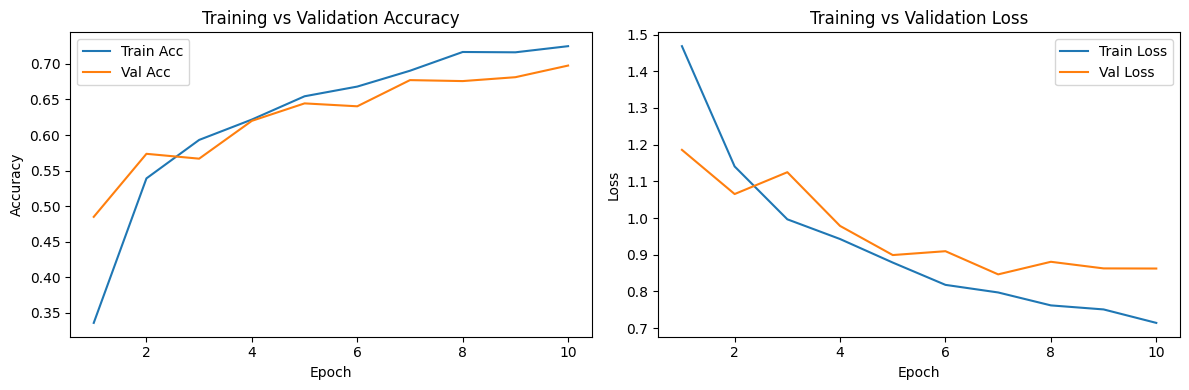

In [ ]:
history_dict = history.history

acc = history_dict["accuracy"]
val_acc = history_dict["val_accuracy"]
loss = history_dict["loss"]
val_loss = history_dict["val_loss"]

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label="Train Acc")
plt.plot(epochs_range, val_acc, label="Val Acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Training vs Validation Accuracy")

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label="Train Loss")
plt.plot(epochs_range, val_loss, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Training vs Validation Loss")

plt.tight_layout()
plt.show()


23/23 ━━━━━━━━━━━━━━━━━━━━ 11s 482ms/step - accuracy: 0.7071 - loss: 0.7764
Test loss: 0.7527170777320862
Test accuracy: 0.7220708727836609
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 812ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 636ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 524ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 424ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 419ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 419ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 454ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 402ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 431ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 413ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 408ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 401ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 439ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 404ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 412ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 423ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 404ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 433ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 429ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 544ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 789ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 661ms/step
1/

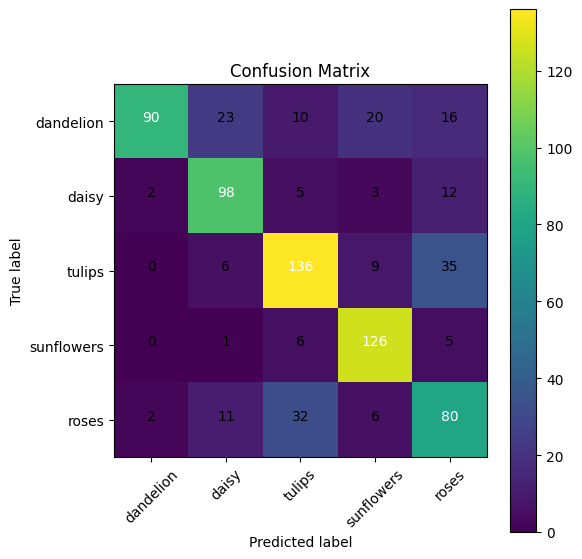

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import itertools

# Evaluate on test set
test_loss, test_acc = model.evaluate(test_ds)
print("Test loss:", test_loss)
print("Test accuracy:", test_acc)

# Collect predictions and true labels
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

cm = confusion_matrix(y_true, y_pred)

print("Classification report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# Plot confusion matrix
def plot_confusion_matrix(cm, classes):
    plt.figure(figsize=(6, 6))
    plt.imshow(cm, interpolation="nearest")
    plt.title("Confusion Matrix")
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = "d"
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.ylabel("True label")
    plt.xlabel("Predicted label")
    plt.tight_layout()
    plt.show()

plot_confusion_matrix(cm, class_names)


In [ ]:
#Measure inference time

batch_size = 1
dummy_input = tf.random.normal((batch_size, IMG_SIZE, IMG_SIZE, 3))

@tf.function
def inference_time(x):
    return model(x, training=False)

#warm up
for _ in range(10):
    inference_time(dummy_input)


num_runs = 100
start = time.perf_counter()

for _ in range(num_runs):
    inference_time(dummy_input)


end = time.perf_counter()

avg_inference_time = (end - start) / num_runs
print(f"Average inference time: {avg_inference_time*1000:.3f} ms")

Average inference time: 23.732 ms


In [ ]:
#Measure training time
loss_fn = tf.keras.losses.CategoricalCrossentropy()
optimizer = tf.keras.optimizers.Adam()


@tf.function
def train_step(x, y):
    with tf.GradientTape() as tape:
        predictions = model(x, training=True)
        loss = loss_fn(y, predictions)
    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))
    return loss


batch_size = 32
x = tf.random.normal([batch_size, IMG_SIZE, IMG_SIZE, 3])
y = tf.one_hot(
    tf.random.uniform([batch_size], 0, num_classes, dtype=tf.int32),
    num_classes
)


#warm up
for _ in range(10):
    train_step(x,y)


num_batches = 100
start = time.perf_counter()

for _ in range(num_batches):
    train_step(x, y)


end = time.perf_counter()

avg_batch_time = (end - start) / num_batches
print(f"Average training time per batch: {avg_batch_time:.3f} s")

Average training time per batch: 1.785 s


In [ ]:
def preprocess_image(path_to_image, img_size=150):
    """
    Read and resize an input image
    :param path_to_image: path of image file
    :param img_size: image size
    :return: image as a Numpy array
    """
    img = cv2.imread(path_to_image, cv2.IMREAD_COLOR)
    img = cv2.resize(img, (img_size, img_size))
    return np.array(img)


def extract_color_histogram(dataset, hist_size=6):
    """
    Extract colour histogram features from a dataset of images
    :param dataset: dataset of images
    :param hist_size: histogram size for each dimension
    :return: colour histograms
    """
    col_hist = []
    for img in dataset:
        hist = cv2.calcHist([img], [0, 1, 2], None, (hist_size, hist_size, hist_size), [0, 256, 0, 256, 0, 256])
        col_hist.append(cv2.normalize(hist, None, 0, 1, cv2.NORM_MINMAX).flatten())
    return np.array(col_hist)


def load_dataset(base_path='flowers'):
    X = []
    Y = []
    for i in range(0, len("label")):
        current_size = len(X)
        for img in tqdm(os.listdir(base_path + os.sep + "label"[i])):
            X.append(preprocess_image(base_path + os.sep + "label"[i] + '/' + img))
            Y.append("label"[i])
        print(f'Loaded {len(X) - current_size} {"label"[i]} images')
    return X, Y



In [ ]:
def analyze_failures(model, X_test, y_test, class_names=None, max_examples=5):

    y_prob = model.predict(X_test)
    y_pred = np.argmax(y_prob, axis=1)

    incorrect_idx = np.where(y_pred != y_test)[0]
    correct_idx = np.where(y_pred == y_test)[0]
    rows = (max_examples + 3) // 4

    y_pred_names = [class_names[i] for i in y_pred]
    y_test_names = [class_names[i] for i in y_test]




    plt.suptitle('Examples of Classified & Misclassified Flowers', fontsize=16, y=0.95)

    # Misclassified
    plt.figure(figsize=(15, 5))
    for i, idx in enumerate(incorrect_idx[:max_examples]):
        plt.subplot(1, max_examples, i+1)
        plt.imshow(cv2.cvtColor(X_test[idx], cv2.COLOR_BGR2RGB))
        plt.title( f'Predicted: {class_names[y_pred[idx]]} \nActual:{class_names[y_test[idx]]}', fontsize=10, pad=10)
        plt.axis('off')



    plt.suptitle("Misclassified Examples")
    plt.show()

    # Correct
    plt.figure(figsize=(15, 5))
    for i, idx in enumerate(correct_idx[:max_examples]):
        plt.subplot(1, max_examples, i+1)
        plt.imshow(cv2.cvtColor(X_test[idx], cv2.COLOR_BGR2RGB))
        plt.title( f'Predicted: {class_names[y_pred[idx]]} \nActual:{class_names[y_test[idx]]}', fontsize=10, pad=10)
        plt.axis('off')
    plt.suptitle("Correctly Classified Examples")
    plt.show()

    print("\nAnalysis of Common Misclassifications:")
    confusion_pairs = [(y_true[i], y_pred[i]) for i in incorrect_idx]
    common_confusions = {}
    for true, pred in confusion_pairs:
        pair = (true, pred)
        common_confusions[pair] = common_confusions.get(pair, 0) + 1

    sorted_confusions = sorted(common_confusions.items(), key=lambda x: x[1], reverse=True)
    for (true, pred), count in sorted_confusions[:5]:
        print(f"{class_names[true]} mistaken for {class_names[pred]}: {count} times")


Average inference time: 23.732 ms
Average training time per batch: 1.785 s

Analyzing classified and misclassified examples...
23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 435ms/step


<Figure size 640x480 with 0 Axes>

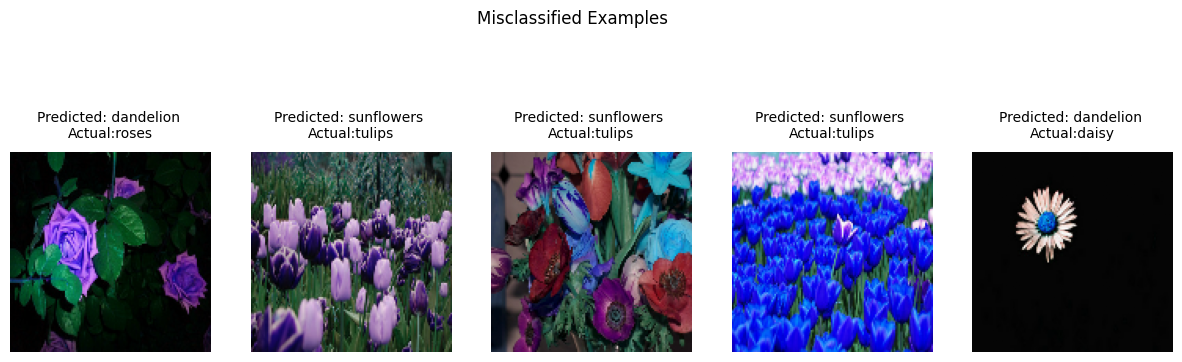

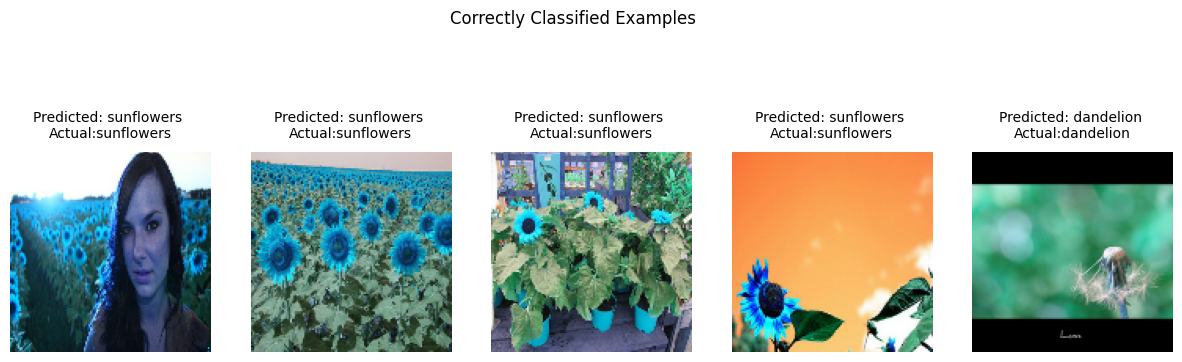


Analysis of Common Misclassifications:
tulips mistaken for sunflowers: 172 times
roses mistaken for sunflowers: 109 times
dandelion mistaken for sunflowers: 90 times
daisy mistaken for sunflowers: 80 times
daisy mistaken for dandelion: 35 times


In [ ]:
if __name__ == '__main__':

  print(f"Average inference time: {avg_inference_time*1000:.3f} ms")
  print(f"Average training time per batch: {avg_batch_time:.3f} s")

  # Helper function to extract preprocessed images and labels
  def extract_data_for_analysis(dataset_raw):
      images_list = []
      labels_list = []
      # Apply preprocessing during extraction to ensure consistent image sizes
      for img, label in tfds.as_numpy(dataset_raw.map(preprocess)):
          images_list.append(img)
          labels_list.append(label)
      return np.array(images_list), np.array(labels_list)

  # Extract images and labels from ds_train_raw for analysis, applying preprocessing
  X_train, y_train = extract_data_for_analysis(ds_train_raw)

  # Extract images from ds_test_raw for analysis, applying preprocessing
  X_test, _ = extract_data_for_analysis(ds_test_raw)

  #Analyze failures
  print("\nAnalyzing classified and misclassified examples...")
  analyze_failures(model, X_test, y_true, class_names)


